# 13. Win probability, WPA, and Clutch

A clutch measure built from win probability (WP), the home team's chance of winning at any moment:

- **WPA** (win probability added): how much each of his goals changed his team's chance of winning, summed over the season
- **xWPA**: what his unblocked shots were worth, given the moments he took them: sum of xGoal x (WPA if it went in)
- **Clutch** = WPA minus his normal finishing (goals / xG, all his unblocked shots) times xWPA. Positive means he scored more in big moments than his usual finishing would predict. Blank under 100 unblocked shots.

The model and the WPA math live in `src/win_prob.py`. The score always comes from MoneyPuck's score-before-shot columns, not from counting goal rows (notebook 11 found 49 goals missing from the shot rows; those columns still include them).

Results go to `data/wpa_by_season.csv` (private). Notebook 10 merges them into the card: WPA and xWPA are rated rows, and Clutch is gray because it doesn't repeat from season to season (section g).

## Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from win_prob import (game_states, fit_wp, wp_home, ot_home_rate, shot_wpa, player_wpa,
                      COEF_NAMES, LATE_GAME_OFFSET, STATE_STEP, HIGH_LEVERAGE)

DATA = Path("../data")
OUT_PATH = DATA / "wpa_by_season.csv"
TRAIN = [2021, 2022, 2023]           # MoneyPuck start years: 2021-22 to 2023-24
TEST = 2025                          # 2025-26; 2024-25 is held back from both
label = lambda y: f"{y}-{str(y + 1)[-2:]}"

shots = pd.read_parquet(DATA / "shots_2021-2025.parquet")
print(f"Regular-season unblocked shots: {len(shots):,}")

Regular-season unblocked shots: 566,158


## a. Game states

One row per game every 10 seconds of regulation, with the latest known score (home minus away), seconds remaining, and whether the home team won. Not one row per shot: that would over-sample the moments when a trailing team is pushing.

In [2]:
states = game_states(shots)
print(f"{len(states):,} game states, one every {STATE_STEP} seconds of regulation")
print(states.groupby("season")["game_id"].nunique().rename(index=label).rename("games").to_string())

2,361,240 game states, one every 10 seconds of regulation
season
2021-22    1311
2022-23    1312
2023-24    1312
2024-25    1312
2025-26    1312


## b. Model

Logistic regression of "home team won" on:
- an intercept (home ice)
- the score difference
- seconds remaining
- score difference / sqrt(seconds remaining + 240): lets a lead matter more as time runs out. The +240 (`LATE_GAME_OFFSET`) was chosen so the model matches how often teams down one goal late actually come back (goalie pulls).

Trained on 2021-22 to 2023-24, tested on 2025-26. The trained model is then used for every season.

In [3]:
train = states[states["season"].isin(TRAIN)]
test = states[states["season"] == TEST].copy()
coef = fit_wp(train)
print(f"Trained on {len(train):,} states ({train['game_id'].groupby(train['season']).nunique().sum():,} games)\n")
print(pd.Series(coef, index=COEF_NAMES).round(4).to_string())

wp = lambda d, s: wp_home(d, s, coef)
print("\nIn plain language:")
print(f"  Home ice: the home team starts at {wp(0, 3600):.1%} to win ({wp(0, 3600) - 0.5:+.1%} over a coin flip).")
for secs, when in [(3600, "at puck drop"), (2400, "at the start of the 2nd"), (1200, "at the start of the 3rd"),
                   (600, "with 10 minutes left"), (120, "with 2 minutes left"), (30, "with 30 seconds left")]:
    print(f"  A 1-goal home lead {when}: {wp(1, secs):.1%} to win ({wp(1, secs) - wp(0, secs):+.1%} vs tied)")

Trained on 1,416,600 states (3,935 games)

intercept (home ice)        0.0876
score diff                 -0.1678
secs remaining / 3600       0.0611
diff / sqrt(secs + 240)    49.5293

In plain language:
  Home ice: the home team starts at 53.7% to win (+3.7% over a coin flip).
  A 1-goal home lead at puck drop: 68.6% to win (+14.9% vs tied)
  A 1-goal home lead at the start of the 2nd: 71.6% to win (+18.4% vs tied)
  A 1-goal home lead at the start of the 3rd: 77.6% to win (+25.0% vs tied)
  A 1-goal home lead with 10 minutes left: 83.7% to win (+31.3% vs tied)
  A 1-goal home lead with 2 minutes left: 92.6% to win (+40.4% vs tied)
  A 1-goal home lead with 30 seconds left: 95.0% to win (+42.8% vs tied)


## c. Overtime

Regular-season overtime and shootouts are handled by rule: a tied overtime moment is worth the home team's actual win rate in games tied after regulation (training seasons), and an overtime goal ends the game (win probability goes to 1 for the scorer).

In [4]:
p_ot, n_ot = ot_home_rate(shots, TRAIN)
print(f"Home win rate in games tied after regulation (training seasons): {p_ot:.3f} ({n_ot:,} games)")

Home win rate in games tied after regulation (training seasons): 0.533 (861 games)


## d. Calibration on the test season (2025-26)

If the model says 70%, the home team should win about 70% of the time. Predicted win probability is binned into tenths and compared with what happened. The Brier score (lower is better) is compared with always guessing the home win rate.

               predicted  actual  states
bin                                     
(-0.001, 0.1]      0.037   0.045   42946
(0.1, 0.2]         0.151   0.174   30187
(0.2, 0.3]         0.251   0.251   28160
(0.3, 0.4]         0.343   0.340   45955
(0.5, 0.6]         0.531   0.503  165527
(0.6, 0.7]         0.694   0.672   11833
(0.7, 0.8]         0.737   0.723   54307
(0.8, 0.9]         0.853   0.855   36769
(0.9, 1.0]         0.963   0.968   56636

Brier score: 0.1752 (always guessing 0.534: 0.2497)


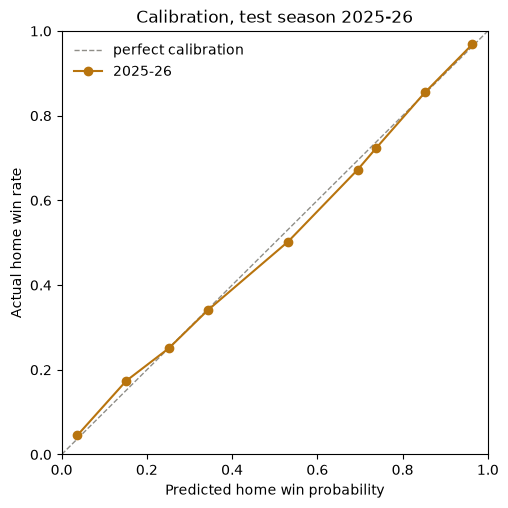

In [5]:
test["p"] = wp_home(test["diff"], test["secs"], coef)
test["bin"] = pd.cut(test["p"], np.linspace(0, 1, 11), include_lowest=True)
calib = test.groupby("bin", observed=True).agg(predicted=("p", "mean"), actual=("home_won", "mean"), states=("p", "size"))
print(calib.round(3).to_string())

brier = np.mean((test["p"] - test["home_won"]) ** 2)
base_rate = train.groupby(["season", "game_id"])["home_won"].first().mean()
baseline = np.mean((base_rate - test["home_won"]) ** 2)
print(f"\nBrier score: {brier:.4f} (always guessing {base_rate:.3f}: {baseline:.4f})")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="#8f8e88", linewidth=1, linestyle="--", label="perfect calibration")
ax.plot(calib["predicted"], calib["actual"], marker="o", color="#b8740e", label="2025-26")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Predicted home win probability", ylabel="Actual home win rate",
       title="Calibration, test season 2025-26")
ax.legend(loc="upper left", frameon=False)
plt.show()

**Late game, the real test.** The overall Brier score can't detect a model that's wrong in the last few minutes, because those moments are a small share of all states. This table shows teams down 1 and down 2 (home or away, from the trailing team's side) by time left, predicted vs actual win rate.

In [6]:
trailing = []
for down in (1, 2):
    home_down = test[test["diff"] == -down].assign(pred=lambda d: d["p"], won=lambda d: d["home_won"])
    away_down = test[test["diff"] == down].assign(pred=lambda d: 1 - d["p"], won=lambda d: 1 - d["home_won"])
    trailing.append(pd.concat([home_down, away_down]).assign(down=f"down {down}"))
trailing = pd.concat(trailing)
trailing = trailing[trailing["secs"] <= 600]
trailing["time left"] = pd.cut(trailing["secs"], [0, 60, 120, 180, 300, 600],
                               labels=["0-1 min", "1-2 min", "2-3 min", "3-5 min", "5-10 min"])
late = trailing.groupby(["down", "time left"], observed=True).agg(
    predicted=("pred", "mean"), actual=("won", "mean"), states=("pred", "size"), games=("game_id", "nunique"))
print(late.assign(predicted=lambda d: d["predicted"].map("{:.1%}".format),
                  actual=lambda d: d["actual"].map("{:.1%}".format)).to_string())

                 predicted actual  states  games
down   time left                                
down 1 0-1 min        5.7%   4.5%    1789    372
       1-2 min        7.4%   8.5%    2421    472
       2-3 min        8.9%  10.4%    2766    491
       3-5 min       11.1%  12.6%    5641    530
       5-10 min      15.3%  15.5%   14296    636
down 2 0-1 min        0.4%   0.0%    1347    307
       1-2 min        0.6%   0.1%    1239    281
       2-3 min        1.0%   1.1%    1289    259
       3-5 min        1.6%   1.9%    3136    312
       5-10 min       3.2%   3.2%    7960    367


## e. Sanity values

In [7]:
print(f"Home win probability at puck drop: {wp(0, 3600):.3f} (expect about 0.53-0.55)")
print(f"Tying goal with 2:00 left (home, down 1 to tied): WPA {wp(0, 120) - wp(-1, 120):+.3f}")
print(f"Go-ahead goal at 0-0, 10:00 into the 1st: WPA {wp(1, 3000) - wp(0, 3000):+.3f}")
print(f"Goal making it 6-1 at the start of the 3rd (home, 5-1 to 6-1): WPA {wp(5, 1200) - wp(4, 1200):+.3f}")
print(f"Overtime winner: home WPA {1 - p_ot:+.3f}, away WPA {p_ot:+.3f}")

Home win probability at puck drop: 0.537 (expect about 0.53-0.55)
Tying goal with 2:00 left (home, down 1 to tied): WPA +0.436
Go-ahead goal at 0-0, 10:00 into the 1st: WPA +0.164
Goal making it 6-1 at the start of the 3rd (home, 5-1 to 6-1): WPA +0.006
Overtime winner: home WPA +0.467, away WPA +0.533


## f. WPA per shot and per player-season

Every unblocked shot gets `wpa_if_goal`: what a goal at that moment would add to his team's win probability. A goal's WPA is its shot's value. Per player-season:
- `wpa` = sum over his goals; `xwpa` = sum over his shots of xGoal x wpa_if_goal
- `finishing` = goals / xG over all his unblocked shots (not shrunk toward average; the last check shows why)
- `clutch` = wpa - finishing x xwpa, blank under 100 unblocked shots
- `hl_goals` = goals worth at least 0.15 of win probability; `ot_goals` = overtime goals

In [8]:
shots_w = shot_wpa(shots, coef, p_ot)
players = player_wpa(shots_w)
players.to_csv(OUT_PATH, index=False)
print(f"Saved data/{OUT_PATH.name}: {OUT_PATH.stat().st_size / 1e6:.1f} MB, {len(players):,} player-seasons (private, gitignored)")

goals = shots_w[shots_w["goal"] == 1]
print(f"Goals: {len(goals):,}; average WPA per goal {goals['wpa_if_goal'].mean():.3f}; "
      f"high-leverage (>= {HIGH_LEVERAGE}): {(goals['wpa_if_goal'] >= HIGH_LEVERAGE).mean():.1%}; "
      f"overtime goals: {int((goals['period'] >= 4).sum())}")

Saved data/wpa_by_season.csv: 0.6 MB, 4,690 player-seasons (private, gitignored)
Goals: 40,412; average WPA per goal 0.161; high-leverage (>= 0.15): 56.7%; overtime goals: 981


## g. Checks

In [9]:
show = ["name", "season_label", "position", "goals", "ot_goals", "hl_goals", "wpa", "xwpa", "finishing", "clutch"]
for col, title in [("wpa", "WPA"), ("xwpa", "xWPA"), ("clutch", "Clutch")]:
    print(f"Top 15 player-seasons by {title}")
    print(players.nlargest(15, col)[show].round(2).to_string(index=False))
    print()

Top 15 player-seasons by WPA
           name season_label position  goals  ot_goals  hl_goals   wpa  xwpa  finishing  clutch
Auston Matthews      2023-24        C     69         3        47 12.14  9.19       1.36   -0.34
  Cole Caufield      2025-26        R     51         5        38 11.38  6.65       1.51    1.32
 Leon Draisaitl      2024-25        C     52         6        34 10.43  5.54       1.67    1.16
 David Pastrnak      2022-23        R     61         4        36 10.13  6.99       1.35    0.68
   Sam Reinhart      2023-24        C     57         3        35 10.00  7.07       1.28    0.93
 Connor McDavid      2022-23        C     63         2        35  9.98  7.22       1.39   -0.08
Auston Matthews      2021-22        C     60         2        29  9.61  7.33       1.43   -0.91
 Leon Draisaitl      2021-22        C     55         1        33  8.44  6.65       1.29   -0.15
 Filip Forsberg      2023-24        L     48         3        28  8.36  6.43       1.24    0.40
  Brayden P

**Repeatability.** If Clutch is a skill, a player's Clutch one season should predict his Clutch the next. Pairs are the same player in seasons t and t+1, with at least 100 unblocked shots in both. WPA and xWPA are season totals, so a player with more ice time looks "repeatable" just from volume; the per-100-shots lines remove that.

In [10]:
q = players[players["unblocked_shots"] >= 100].copy()
for col in ["wpa", "xwpa", "clutch"]:
    q[f"{col}_per100"] = q[col] / q["unblocked_shots"] * 100
pairs = q.merge(q.assign(season=q["season"] - 1), on=["playerId", "season"], suffixes=("_t", "_t1"))

rows = []
for col, name in [("clutch", "Clutch"), ("wpa", "WPA"), ("xwpa", "xWPA"),
                  ("clutch_per100", "Clutch per 100 shots"), ("wpa_per100", "WPA per 100 shots"), ("xwpa_per100", "xWPA per 100 shots")]:
    row = {"stat": name}
    for pos, pos_name in [("F", "Forwards"), ("D", "Defense")]:
        g = pairs[pairs["pos_group_t"] == pos]
        row[f"{pos_name} r"] = g[f"{col}_t"].corr(g[f"{col}_t1"])
    rows.append(row)
print("Year-to-year correlation (season t vs t+1, 100+ unblocked shots both seasons)")
print(pd.DataFrame(rows).set_index("stat").round(2).to_string())
print(f"Pairs: forwards {int((pairs['pos_group_t'] == 'F').sum())}, defense {int((pairs['pos_group_t'] == 'D').sum())}")

Year-to-year correlation (season t vs t+1, 100+ unblocked shots both seasons)
                      Forwards r  Defense r
stat                                       
Clutch                      0.07       0.06
WPA                         0.64       0.51
xWPA                        0.71       0.76
Clutch per 100 shots        0.05       0.09
WPA per 100 shots           0.33       0.24
xWPA per 100 shots          0.55       0.58
Pairs: forwards 1119, defense 459


**Is Clutch just "scores a lot"?** If Clutch were mostly volume, it would track goals and xWPA closely.

In [11]:
print("Correlation with Clutch (player-seasons with 100+ unblocked shots)")
for pos, pos_name in [("F", "Forwards"), ("D", "Defense"), (None, "All")]:
    g = q if pos is None else q[q["pos_group"] == pos]
    print(f"  {pos_name}: goals r = {g['clutch'].corr(g['goals']):+.2f}, xWPA r = {g['clutch'].corr(g['xwpa']):+.2f} (n = {len(g)})")

print("\nKnown gap: about 49 goals are missing from the shot rows (notebook 11). The score-before columns include them,")
print("so every other shot's game state is right, but those goals' own WPA is not credited to anyone.")

Correlation with Clutch (player-seasons with 100+ unblocked shots)
  Forwards: goals r = +0.05, xWPA r = -0.02 (n = 1705)
  Defense: goals r = +0.11, xWPA r = +0.05 (n = 741)
  All: goals r = +0.02, xWPA r = -0.04 (n = 2446)

Known gap: about 49 goals are missing from the shot rows (notebook 11). The score-before columns include them,
so every other shot's game state is right, but those goals' own WPA is not credited to anyone.


**Why Clutch uses unshrunk finishing.** Clutch was first defined with finishing shrunk toward average, (goals + 10) / (xG + 10). That shrink pulls a good finisher's rate down, so his goals above the shrunk rate land in Clutch even when they come in ordinary moments. This check recomputes that first version and compares it with Clutch as used now (unshrunk).

- If the first version tracks the finishing the shrink leaves behind, it was mostly measuring finishing, not big-moment scoring.
- If the first version is much more repeatable than the unshrunk one, that repeatability came from finishing (a real, repeatable skill), not from clutch.

In [12]:
q["finishing_shrunk"] = (q["goals"] + 10) / (q["xg"] + 10)
q["clutch_shrunk"] = q["wpa"] - q["finishing_shrunk"] * q["xwpa"]
q["leftover_finishing"] = (q["finishing"] - q["finishing_shrunk"]) * q["xwpa"]

print("Correlations (player-seasons with 100+ unblocked shots)")
for pos, pos_name in [("F", "Forwards"), ("D", "Defense")]:
    g = q[q["pos_group"] == pos]
    print(f"  {pos_name}: first version (+10 shrink) vs leftover finishing r = {g['clutch_shrunk'].corr(g['leftover_finishing']):+.2f}, "
          f"vs goals / xG r = {g['clutch_shrunk'].corr(g['finishing']):+.2f}; "
          f"Clutch now vs goals r = {g['clutch'].corr(g['goals']):+.2f}")

pairs = q.merge(q.assign(season=q["season"] - 1), on=["playerId", "season"], suffixes=("_t", "_t1"))
print("\nYear-to-year correlation (same pairs as above)")
rows = []
for col, name in [("clutch_shrunk", "Clutch as first defined (+10 shrink)"), ("clutch", "Clutch now (unshrunk)"),
                  ("finishing", "Finishing (goals / xG)")]:
    rows.append({"stat": name, **{f"{pos_name} r": pairs[pairs["pos_group_t"] == pos][f"{col}_t"]
                                  .corr(pairs[pairs["pos_group_t"] == pos][f"{col}_t1"])
                                  for pos, pos_name in [("F", "Forwards"), ("D", "Defense")]}})
print(pd.DataFrame(rows).set_index("stat").round(2).to_string())

Correlations (player-seasons with 100+ unblocked shots)
  Forwards: first version (+10 shrink) vs leftover finishing r = +0.61, vs goals / xG r = +0.59; Clutch now vs goals r = +0.05
  Defense: first version (+10 shrink) vs leftover finishing r = +0.71, vs goals / xG r = +0.66; Clutch now vs goals r = +0.11

Year-to-year correlation (same pairs as above)
                                      Forwards r  Defense r
stat                                                       
Clutch as first defined (+10 shrink)        0.20       0.06
Clutch now (unshrunk)                       0.07       0.06
Finishing (goals / xG)                      0.33      -0.03
